# Johns Pipeline 2 — Light Gradient Boosting Machine (LightGBM) Synthetic Weather→Unusual-Order Demo

## Business question

> **Based on the upcoming weather forecast, is there a chance Johns will receive unusual / unplanned aggregate orders during the next few weeks, irrespective of which retailer places them?**

This notebook is a **demo / experimentation notebook**. It uses:

- Johns **aggregate daily sales revenue** from Odoo (`sale_order`), summed across all retailers.
- Long historical rainfall data from Open-Meteo.
- The real Johns series only to learn approximate sales characteristics such as month pattern, weekday pattern, zeros, variability, and spike scale.
- A transparent **semi-synthetic generator** to create a longer multi-year demo history.
- Explicit simulated rules that make very wet / prolonged-rain forecast windows more likely to create a later unusual aggregate order surge.
- A **Light Gradient Boosting Machine (LightGBM) classifier** for separate 7-, 14-, and 21-day targets.

### Critical interpretation

The LightGBM model in this notebook learns the relationship that **we intentionally simulate**. Therefore its probability is a **demo-model probability under the synthetic assumptions**, not a validated real-world probability that Johns will receive an unusual order.

The purpose is to demonstrate the full architecture now. When sufficient real Johns history and confirmed unusual-replenishment labels become available, replace the synthetic target with the real target and retrain.


## Architecture

```text
REAL JOHNS DAILY SALES (about 1.6 years)
              │
              ├── learn month / weekday / zero / residual / spike characteristics
              │
LONG HISTORICAL WEATHER
              │
              └──────────────┐
                             ↓
                 SEMI-SYNTHETIC GENERATOR
                             │
             normal synthetic Johns baseline
                             +
             transparent weather-driven surge rules
                             ↓
                  multi-year demo history
                             │
                  feature engineering
                             │
           ┌─────────────────┼─────────────────┐
           ↓                 ↓                 ↓
      7-day target      14-day target     21-day target
           ↓                 ↓                 ↓
       LightGBM           LightGBM           LightGBM
           └─────────────────┼─────────────────┘
                             ↓
                  future weather forecast
                             ↓
              demo unusual-order risk score
```

**Retailer-wise sales are not required for this aggregate experiment.** The target is whether *any aggregate unusual order activity* occurs within the future horizon.


## 1. Export aggregate Johns daily sales from PostgreSQL / Odoo

Run this in pgAdmin and export the result as `johns_daily_sales.csv`.

This query creates a complete daily calendar and sums confirmed Odoo sales orders across all retailers.

```sql
WITH params AS (
    SELECT
        DATE '2025-01-06' AS start_date,
        (CURRENT_TIMESTAMP AT TIME ZONE 'Asia/Kolkata')::date AS end_date
),
dates AS (
    SELECT generate_series(
        (SELECT start_date FROM params),
        (SELECT end_date FROM params),
        INTERVAL '1 day'
    )::date AS sale_date
),
sales AS (
    SELECT
        (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,
        SUM(so.amount_total) AS daily_sales_total,
        COUNT(DISTINCT so.id) AS order_count
    FROM sale_order so
    CROSS JOIN params p
    WHERE so.state IN ('sale', 'done')
      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date BETWEEN p.start_date AND p.end_date
    GROUP BY 1
)
SELECT
    d.sale_date,
    COALESCE(s.daily_sales_total, 0) AS daily_sales_total,
    COALESCE(s.order_count, 0) AS order_count
FROM dates d
LEFT JOIN sales s USING (sale_date)
ORDER BY d.sale_date;
```

Only `sale_date` and `daily_sales_total` are required by this notebook. `order_count` is retained because it can become a useful feature later.


## 2. Install packages


In [65]:
%pip install -q pandas numpy matplotlib scikit-learn lightgbm requests joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Imports and configuration


In [66]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import joblib

import lightgbm as lgb
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# -----------------------------
# Files
# -----------------------------
REAL_SALES_CSV = Path("../input/johns_daily_sales.csv")
EXPORT_DIR = Path("johns_lightgbm_demo_outputs")
EXPORT_DIR.mkdir(exist_ok=True)

# -----------------------------
# One-location demo assumption
# -----------------------------
LOCATION_NAME = "Kozhikode"
COUNTRY_CODE = "IN"

# -----------------------------
# Weather history
# -----------------------------
WEATHER_HISTORY_START = "2010-01-01"
WEATHER_HISTORY_END = (
    pd.Timestamp.today().normalize() - pd.Timedelta(days=7)
).strftime("%Y-%m-%d")

RAINY_DAY_MM = 0.1
HEAVY_RAIN_DAY_MM = 20.0
VERY_WET_DAY_MM = 50.0

# -----------------------------
# Synthetic demo
# -----------------------------
SYNTHETIC_YEARS = 10
RANDOM_STATE = 42
RNG = np.random.default_rng(RANDOM_STATE)

# The simulated unusual-order event is deliberately rare.
BASE_TRIGGER_PROBABILITY = 0.005
TRIGGER_PRESSURE_START = 0.80
MAX_TRIGGER_PROBABILITY = 0.55
EVENT_COOLDOWN_DAYS = 12
MIN_EVENT_DELAY_DAYS = 3
MAX_EVENT_DELAY_DAYS = 10

# Separate LightGBM targets.
HORIZONS = [7, 14, 21]

# -----------------------------
# Model
# -----------------------------
SALES_SCALE = 1_000_000.0
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
# Remaining 15% = untouched chronological test set.

MODEL_PARAMS = {
    "objective": "binary",
    "n_estimators": 450,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "max_depth": 5,
    "min_child_samples": 30,
    "subsample": 0.85,
    "subsample_freq": 1,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.2,
    "reg_lambda": 1.0,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1,
}

# Live scoring is allowed only if the sales export is reasonably current.
MAX_LIVE_SALES_STALENESS_DAYS = 2

print("LightGBM version:", lgb.__version__)
print("Today:", pd.Timestamp.today().normalize().date())


LightGBM version: 4.7.0
Today: 2026-09-01


## 4. Load and prepare real Johns daily sales

The real series is **not duplicated** to pretend that more history exists. It is used to estimate a compact empirical template for the synthetic generator.


In [35]:
if not REAL_SALES_CSV.exists():
    raise FileNotFoundError(
        f"Missing {REAL_SALES_CSV.resolve()}\n"
        "Run the PostgreSQL query above, export the result as johns_daily_sales.csv, "
        "place it beside this notebook, and rerun."
    )

raw_sales = pd.read_csv(REAL_SALES_CSV)

DATE_CANDIDATES = ["sale_date", "date", "day"]
SALES_CANDIDATES = ["daily_sales_total", "daily_sales", "sales"]
ORDER_COUNT_CANDIDATES = ["order_count", "orders", "daily_order_count"]

date_col = next((c for c in DATE_CANDIDATES if c in raw_sales.columns), None)
sales_col = next((c for c in SALES_CANDIDATES if c in raw_sales.columns), None)
order_count_col = next((c for c in ORDER_COUNT_CANDIDATES if c in raw_sales.columns), None)

if date_col is None or sales_col is None:
    raise KeyError(
        "Expected a supported date and sales column. "
        f"Found columns: {list(raw_sales.columns)}"
    )

keep_cols = [date_col, sales_col] + ([order_count_col] if order_count_col else [])
real_sales = raw_sales[keep_cols].copy()
real_sales = real_sales.rename(columns={date_col: "date", sales_col: "sales"})
if order_count_col:
    real_sales = real_sales.rename(columns={order_count_col: "order_count"})

real_sales["date"] = pd.to_datetime(real_sales["date"])
real_sales["sales"] = pd.to_numeric(real_sales["sales"], errors="coerce").fillna(0.0)
if "order_count" in real_sales.columns:
    real_sales["order_count"] = pd.to_numeric(real_sales["order_count"], errors="coerce").fillna(0.0)

real_sales = (
    real_sales.groupby("date", as_index=True)
    .agg({"sales": "sum", **({"order_count": "sum"} if "order_count" in real_sales.columns else {})})
    .sort_index()
)

full_index = pd.date_range(real_sales.index.min(), real_sales.index.max(), freq="D")
real_sales = real_sales.reindex(full_index)
real_sales.index.name = "date"
real_sales["sales"] = real_sales["sales"].fillna(0.0)
if "order_count" in real_sales.columns:
    real_sales["order_count"] = real_sales["order_count"].fillna(0.0)

print("Real Johns range:", real_sales.index.min().date(), "->", real_sales.index.max().date())
print("Calendar days:", len(real_sales))
print("Zero-sales days:", int((real_sales["sales"] == 0).sum()))
print("Zero-sales %:", round((real_sales["sales"] == 0).mean() * 100, 2))
display(real_sales.head())
display(real_sales.tail())


Real Johns range: 2025-01-06 -> 2026-08-07
Calendar days: 579
Zero-sales days: 205
Zero-sales %: 35.41


,sales
date,
2025-01-06,5796829.52
2025-01-07,903355.24
2025-01-08,121297.50
2025-01-09,0.00
2025-01-10,357332.86


,sales
date,
2026-08-03,0.00
2026-08-04,506453.86
2026-08-05,589163.42
2026-08-06,215680.50
2026-08-07,7799.40


## 5. Inspect the real aggregate series


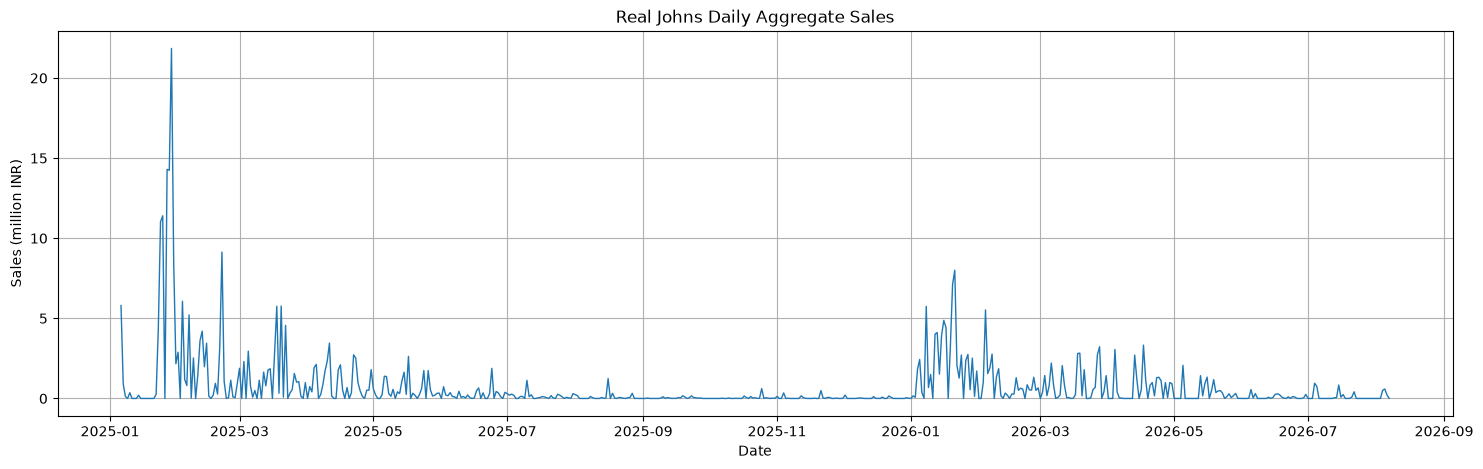

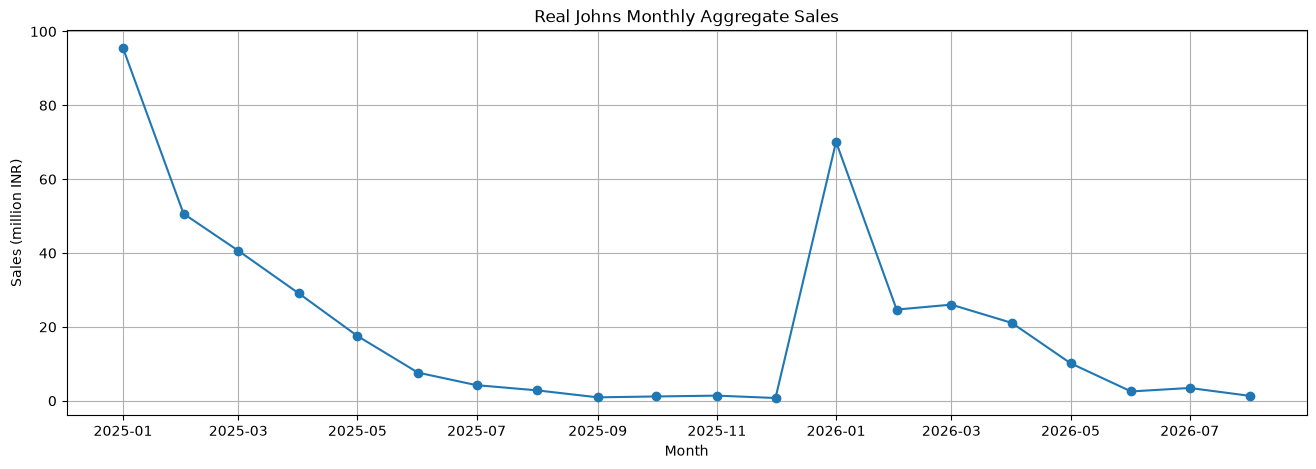

count    5.790000e+02
mean     7.111291e+05
std      1.808549e+06
min      0.000000e+00
50%      6.024900e+04
75%      5.517437e+05
90%      1.990909e+06
95%      3.230629e+06
99%      8.667164e+06
max      2.184477e+07
Name: sales, dtype: float64

In [36]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(real_sales.index, real_sales["sales"] / SALES_SCALE, linewidth=1)
ax.set_title("Real Johns Daily Aggregate Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sales (million INR)")
ax.grid(True)
plt.show()

monthly_real = real_sales["sales"].resample("MS").sum() / SALES_SCALE
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(monthly_real.index, monthly_real.values, marker="o")
ax.set_title("Real Johns Monthly Aggregate Sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (million INR)")
ax.grid(True)
plt.show()

display(real_sales["sales"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))


# Part A — Long historical weather

The notebook keeps the previous Pipeline 2 simplification: all retailers are temporarily represented by one location. Change `LOCATION_NAME` if needed.


## 6. Geocode the demo location


In [37]:
def geocode_open_meteo(location_name, country_code=None):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": location_name,
        "count": 10,
        "language": "en",
        "format": "json",
    }
    if country_code:
        params["countryCode"] = country_code

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    results = response.json().get("results", [])
    if not results:
        raise ValueError(f"No Open-Meteo geocoding result for {location_name}")

    x = results[0]
    return {
        "name": x.get("name"),
        "admin1": x.get("admin1"),
        "country": x.get("country"),
        "latitude": x["latitude"],
        "longitude": x["longitude"],
        "timezone": x.get("timezone", "Asia/Kolkata"),
    }

location = geocode_open_meteo(LOCATION_NAME, COUNTRY_CODE)
location


{'name': 'Kozhikode',
 'admin1': 'Kerala',
 'country': 'India',
 'latitude': 11.24802,
 'longitude': 75.7804,
 'timezone': 'Asia/Kolkata'}

## 7. Download historical daily rainfall


In [38]:
def fetch_historical_weather(latitude, longitude, start_date, end_date, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "precipitation_unit": "mm",
    }

    response = requests.get(url, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()
    if "daily" not in payload:
        raise ValueError(f"Unexpected Open-Meteo response: {payload}")

    df = pd.DataFrame(payload["daily"])
    df["date"] = pd.to_datetime(df["time"])
    df = df.drop(columns=["time"]).set_index("date").sort_index()

    for col in ["rain_sum", "precipitation_sum", "precipitation_hours"]:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    return df

historical_weather = fetch_historical_weather(
    location["latitude"],
    location["longitude"],
    WEATHER_HISTORY_START,
    WEATHER_HISTORY_END,
    location["timezone"],
)

print("Historical weather:", historical_weather.index.min().date(), "->", historical_weather.index.max().date())
print("Rows:", len(historical_weather))
display(historical_weather.head())


Historical weather: 2010-01-01 -> 2026-08-25
Rows: 6081


,rain_sum,precipitation_sum,precipitation_hours
date,,,
2010-01-01,0.9,0.9,3.0
2010-01-02,0.0,0.0,0.0
2010-01-03,1.5,1.5,6.0
2010-01-04,0.0,0.0,0.0
2010-01-05,0.0,0.0,0.0


## 8. Historical rainfall overview


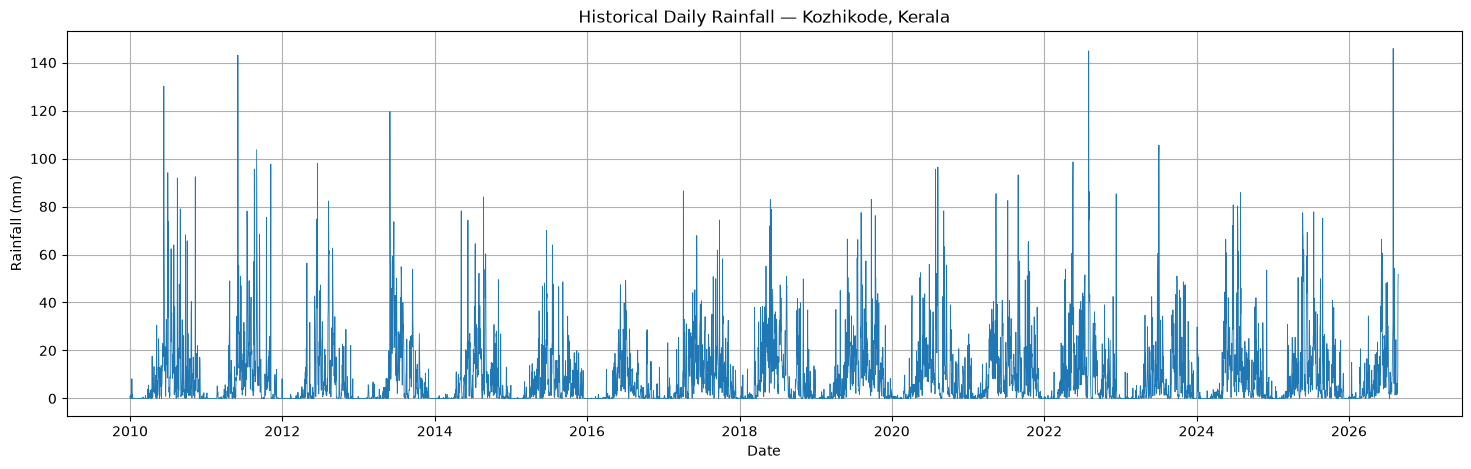

,mean_daily_rain_mm
date,
1,0.812903
2,0.461875
3,1.842884
4,6.822353
5,13.517268
6,21.445294
7,18.784061
8,15.906142
9,11.015833


In [39]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(historical_weather.index, historical_weather["rain_sum"], linewidth=0.6)
ax.set_title(f"Historical Daily Rainfall — {location['name']}, {location.get('admin1')}")
ax.set_xlabel("Date")
ax.set_ylabel("Rainfall (mm)")
ax.grid(True)
plt.show()

monthly_rain_climatology = historical_weather.groupby(historical_weather.index.month)["rain_sum"].mean()
display(monthly_rain_climatology.rename("mean_daily_rain_mm").to_frame())


# Part B — Learn a compact sales template from real Johns data

We do **not** create 10 synthetic years by repeatedly copying the existing rows. Instead, we estimate:

- typical log-sales level,
- month effects,
- weekday effects,
- residual distribution,
- month-specific probability of a zero-sales day,
- rough upper scale for clipping unrealistic generated values.

The synthetic generator then samples from these components.


## 9. Estimate month / weekday / residual characteristics


In [40]:
def learn_real_sales_template(real_sales_df):
    x = real_sales_df.copy()
    x["month"] = x.index.month
    x["day_of_week"] = x.index.dayofweek
    x["log_sales"] = np.log1p(x["sales"].clip(lower=0))

    global_log = float(x["log_sales"].median())

    month_median = x.groupby("month")["log_sales"].median()
    month_effect = month_median - global_log

    x["after_month"] = x["log_sales"] - x["month"].map(month_effect) - global_log
    dow_effect = x.groupby("day_of_week")["after_month"].median()

    fitted_log = (
        global_log
        + x["month"].map(month_effect).fillna(0.0)
        + x["day_of_week"].map(dow_effect).fillna(0.0)
    )
    residuals = (x["log_sales"] - fitted_log).dropna().values

    zero_probability = x.assign(is_zero=(x["sales"] <= 0).astype(int)).groupby("month")["is_zero"].mean()

    positive_sales = x.loc[x["sales"] > 0, "sales"]
    positive_median = float(positive_sales.median()) if len(positive_sales) else 1.0
    upper_clip = float(x["sales"].quantile(0.997)) if len(x) else 1.0
    upper_clip = max(upper_clip, positive_median * 5)

    return {
        "global_log": global_log,
        "month_effect": month_effect.to_dict(),
        "dow_effect": dow_effect.to_dict(),
        "residuals": residuals,
        "zero_probability": zero_probability.to_dict(),
        "positive_median": positive_median,
        "upper_clip": upper_clip,
    }

template = learn_real_sales_template(real_sales)

print("Global median log-sales:", round(template["global_log"], 3))
print("Positive-sales median:", round(template["positive_median"], 2))
print("Residual pool size:", len(template["residuals"]))
print("Month zero probabilities:")
display(pd.Series(template["zero_probability"], name="zero_probability").to_frame())


Global median log-sales: 11.006
Positive-sales median: 323761.73
Residual pool size: 579
Month zero probabilities:


,zero_probability
1,0.280702
2,0.160714
3,0.209677
4,0.300000
5,0.322581
6,0.316667
7,0.467742
8,0.447368
9,0.433333
10,0.483871


## 10. Compare learned month effects


In [41]:
month_effect_table = pd.DataFrame({
    "month": range(1, 13),
    "month_effect_log": [template["month_effect"].get(m, 0.0) for m in range(1, 13)],
})
month_effect_table["relative_factor"] = np.exp(month_effect_table["month_effect_log"])
display(month_effect_table)


,month,month_effect_log,relative_factor
0,1,3.048345,21.080424
1,2,2.380547,10.810820
2,3,2.210137,9.116963
3,4,2.145820,8.549051
4,5,1.353430,3.870678
5,6,0.046471,1.047568
6,7,-1.639857,0.194008
7,8,-1.820787,0.161898
8,9,-1.714999,0.179964
9,10,-3.342193,0.035359


# Part C — Build the semi-synthetic multi-year history

### Synthetic baseline

For each synthetic date:

1. start from the real Johns global log-sales level,
2. add the learned month effect,
3. add the learned weekday effect,
4. add a small year-to-year drift,
5. bootstrap a residual from the real data,
6. reproduce approximately the real zero-sales frequency by month,
7. optionally create a small number of unrelated normal business spikes.

This generates the **normal baseline** before any simulated weather-driven unusual-order event is injected.


## 11. Choose the synthetic date range


In [42]:
weather_end = historical_weather.index.max().normalize()
weather_start = historical_weather.index.min().normalize()

candidate_start = weather_end - pd.DateOffset(years=SYNTHETIC_YEARS) + pd.Timedelta(days=1)
synthetic_start = max(weather_start, candidate_start)
synthetic_end = weather_end
synthetic_dates = pd.date_range(synthetic_start, synthetic_end, freq="D")

print("Synthetic demo range:", synthetic_start.date(), "->", synthetic_end.date())
print("Synthetic days:", len(synthetic_dates))


Synthetic demo range: 2016-08-26 -> 2026-08-25
Synthetic days: 3652


## 12. Generate normal synthetic Johns sales


In [43]:
def generate_synthetic_baseline(dates, template, rng):
    out = pd.DataFrame(index=dates)
    out.index.name = "date"
    out["month"] = out.index.month
    out["day_of_week"] = out.index.dayofweek
    out["year"] = out.index.year
    
    unique_years = sorted(out["year"].unique())
    # Mild multiplicative year-to-year change on the log scale.
    year_effects = {year: rng.normal(0.0, 0.08) for year in unique_years}

    residual_pool = np.asarray(template["residuals"], dtype=float)
    if len(residual_pool) == 0:
        residual_pool = np.array([0.0])

    sampled_residual = rng.choice(residual_pool, size=len(out), replace=True)
    # Shrink bootstrapped residuals slightly to avoid exaggerated repetition of extreme real spikes.
    sampled_residual = sampled_residual * 0.80

    base_log = (
        template["global_log"]
        + out["month"].map(template["month_effect"]).fillna(0.0).values
        + out["day_of_week"].map(template["dow_effect"]).fillna(0.0).values
        + out["year"].map(year_effects).values
        + sampled_residual
    )

    baseline_sales = np.expm1(base_log)
    baseline_sales = np.clip(baseline_sales, 0.0, template["upper_clip"] * 1.5)

    # Reproduce zero-sales days approximately by month.
    zero_prob = out["month"].map(template["zero_probability"]).fillna(0.0).values
    zero_draw = rng.random(len(out)) < zero_prob
    baseline_sales[zero_draw] = 0.0

    # Rare non-weather business spikes, so weather is not the only reason sales can jump.
    unrelated_spike = rng.random(len(out)) < 0.012
    unrelated_multiplier = rng.uniform(1.25, 2.2, size=len(out))
    baseline_sales = np.where(unrelated_spike, baseline_sales * unrelated_multiplier, baseline_sales)

    out["baseline_sales"] = baseline_sales
    out["unrelated_business_spike"] = unrelated_spike.astype(int)
    return out

synthetic = generate_synthetic_baseline(synthetic_dates, template, RNG)

synthetic = synthetic.join(
    historical_weather[["rain_sum", "precipitation_sum", "precipitation_hours"]],
    how="left",
)

if synthetic[["rain_sum", "precipitation_sum", "precipitation_hours"]].isna().any().any():
    raise ValueError("Missing historical weather inside the selected synthetic range.")

print("Synthetic rows:", len(synthetic))
display(synthetic.head())


Synthetic rows: 3652


,month,day_of_week,year,baseline_sales,unrelated_business_spike,rain_sum,precipitation_sum,precipitation_hours
date,,,,,,,,
2016-08-26,8,4,2016,0.000000,0,10.7,10.7,13.0
2016-08-27,8,5,2016,0.305881,0,3.9,3.9,12.0
2016-08-28,8,6,2016,0.000000,0,4.2,4.2,15.0
2016-08-29,8,0,2016,0.000000,0,4.2,4.2,14.0
2016-08-30,8,1,2016,50620.827953,0,18.8,18.8,22.0


## 13. Create observed-weather and future-weather features

For model training, the future weather values below use **historically realized weather as a perfect-forecast proxy**. This is acceptable only for this architecture demo.

A rigorous real historical backtest should use forecasts that were actually issued at that time (for example a historical forecast archive), because realized future rainfall is more accurate than a real forecast would have been.


In [44]:
def add_weather_features(df, horizons):
    x = df.copy()
    
    rain = x["rain_sum"].astype(float)
    ph = x["precipitation_hours"].astype(float)
    
    # Weather observed by the anchor date.
    x["rain_last_3d"] = rain.rolling(3, min_periods=3).sum()
    x["rain_last_7d"] = rain.rolling(7, min_periods=7).sum()
    x["rain_last_14d"] = rain.rolling(14, min_periods=14).sum()
    x["rainy_days_last_7d"] = (rain >= RAINY_DAY_MM).astype(int).rolling(7, min_periods=7).sum()
    x["heavy_days_last_14d"] = (rain >= HEAVY_RAIN_DAY_MM).astype(int).rolling(14, min_periods=14).sum()
    x["max_rain_last_7d"] = rain.rolling(7, min_periods=7).max()
    x["precip_hours_last_7d"] = ph.rolling(7, min_periods=7).sum()

    # Next-h-day forecast-style features, excluding the anchor day.
    # rolling(h).agg().shift(-h) at day t summarizes t+1 ... t+h.
    for h in horizons:
        x[f"forecast_rain_{h}d"] = rain.rolling(h, min_periods=h).sum().shift(-h)
        x[f"forecast_rainy_days_{h}d"] = (
            (rain >= RAINY_DAY_MM).astype(int).rolling(h, min_periods=h).sum().shift(-h)
        )
        x[f"forecast_heavy_days_{h}d"] = (
            (rain >= HEAVY_RAIN_DAY_MM).astype(int).rolling(h, min_periods=h).sum().shift(-h)
        )
        x[f"forecast_very_wet_days_{h}d"] = (
            (rain >= VERY_WET_DAY_MM).astype(int).rolling(h, min_periods=h).sum().shift(-h)
        )
        x[f"forecast_max_daily_rain_{h}d"] = rain.rolling(h, min_periods=h).max().shift(-h)
        x[f"forecast_precip_hours_{h}d"] = ph.rolling(h, min_periods=h).sum().shift(-h)

    return x

synthetic = add_weather_features(synthetic, HORIZONS)
display(synthetic.filter(regex="rain|precip").head(20))


,rain_sum,precipitation_sum,precipitation_hours,rain_last_3d,rain_last_7d,rain_last_14d,rainy_days_last_7d,max_rain_last_7d,precip_hours_last_7d,forecast_rain_7d,...,forecast_max_daily_rain_7d,forecast_precip_hours_7d,forecast_rain_14d,forecast_rainy_days_14d,forecast_max_daily_rain_14d,forecast_precip_hours_14d,forecast_rain_21d,forecast_rainy_days_21d,forecast_max_daily_rain_21d,forecast_precip_hours_21d
date,,,,,,,,,,,,,,,,,,,,,
2016-08-26,10.7,10.7,13.0,NaN,NaN,NaN,NaN,NaN,NaN,75.8,...,20.2,131.0,84.1,14.0,20.2,168.0,99.1,20.0,20.2,222.0
2016-08-27,3.9,3.9,12.0,NaN,NaN,NaN,NaN,NaN,NaN,76.3,...,20.2,134.0,80.4,14.0,20.2,157.0,100.2,20.0,20.2,229.0
2016-08-28,4.2,4.2,15.0,18.8,NaN,NaN,NaN,NaN,NaN,72.6,...,20.2,124.0,76.2,13.0,20.2,142.0,101.0,20.0,20.2,228.0
2016-08-29,4.2,4.2,14.0,12.3,NaN,NaN,NaN,NaN,NaN,69.0,...,20.2,112.0,73.3,13.0,20.2,134.0,97.9,20.0,20.2,220.0
2016-08-30,18.8,18.8,22.0,27.2,NaN,NaN,NaN,NaN,NaN,51.2,...,20.2,94.0,56.0,13.0,20.2,118.0,79.4,20.0,20.2,200.0
2016-08-31,20.2,20.2,24.0,43.2,NaN,NaN,NaN,NaN,NaN,31.8,...,14.6,75.0,39.6,13.0,14.6,105.0,59.2,19.0,14.6,176.0
2016-09-01,9.9,9.9,22.0,48.9,71.9,NaN,7.0,20.2,122.0,22.5,...,14.6,57.0,32.5,13.0,14.6,95.0,50.1,19.0,14.6,159.0
2016-09-02,14.6,14.6,22.0,44.7,75.8,NaN,7.0,20.2,131.0,8.3,...,4.4,37.0,23.3,13.0,5.4,91.0,37.6,19.0,5.4,146.0
2016-09-03,4.4,4.4,15.0,28.9,76.3,NaN,7.0,20.2,134.0,4.1,...,1.0,23.0,23.9,13.0,5.4,95.0,35.4,19.0,5.4,145.0


# Part D — Transparently simulate unusual aggregate order events

We need labelled `0/1` targets to train a supervised classifier. Since Johns does not yet have confirmed historical labels such as `weather_driven_unusual_order = 1`, this notebook deliberately creates them.

### Demo rule

The generator computes a 7-day **future weather pressure** from:

- total rainfall percentile for the month,
- number of rainy days percentile,
- maximum single-day rainfall percentile.

When weather pressure becomes unusually high, the probability of scheduling a synthetic unusual order event 3–10 days later increases. A cooldown prevents unrealistic events every day.

These rules are **assumptions for the demo**, not measured Johns business probabilities.


## 14. Compute synthetic weather pressure


In [67]:
def within_month_percentile(series, month_index):
    temp = pd.DataFrame({"value": series, "month": month_index}, index=series.index)
    return temp.groupby("month")["value"].rank(pct=True)

synthetic["forecast_rain_7d_pct"] = within_month_percentile(
    synthetic["forecast_rain_7d"], synthetic.index.month
)
synthetic["forecast_rainy_days_7d_pct"] = within_month_percentile(
    synthetic["forecast_rainy_days_7d"], synthetic.index.month
)
synthetic["forecast_max_daily_rain_7d_pct"] = within_month_percentile(
    synthetic["forecast_max_daily_rain_7d"], synthetic.index.month
)

synthetic["weather_pressure"] = (
    0.55 * synthetic["forecast_rain_7d_pct"]
    + 0.25 * synthetic["forecast_rainy_days_7d_pct"]
    + 0.20 * synthetic["forecast_max_daily_rain_7d_pct"]
)

synthetic[[
    "forecast_rain_7d",
    "forecast_rain_7d_pct",
    "forecast_rainy_days_7d_pct",
    "forecast_max_daily_rain_7d_pct",
    "weather_pressure",
]].describe()


,forecast_rain_7d,forecast_rain_7d_pct,forecast_rainy_days_7d_pct,forecast_max_daily_rain_7d_pct,weather_pressure
count,3645.000000,3645.000000,3645.000000,3645.000000,3645.000000
mean,69.430782,0.501646,0.501646,0.501646,0.501646
std,74.012887,0.288584,0.224948,0.288503,0.251204
min,0.000000,0.003226,0.003226,0.003226,0.003333
25%,9.200000,0.251613,0.409677,0.251613,0.295833
50%,48.600000,0.501650,0.554839,0.500000,0.517903
75%,107.500000,0.751667,0.630000,0.751613,0.713209
max,499.400000,1.000000,0.977419,1.000000,0.991935


## 15. Inject synthetic unusual-order events


In [ ]:
def inject_weather_driven_events(df, template, rng):
    x = df.copy()
    n = len(x)
    event = np.zeros(n, dtype=int)
    event_source_pressure = np.full(n, np.nan)
    event_trigger_date = np.full(n, np.datetime64("NaT"), dtype="datetime64[ns]")
    last_scheduled_event_idx = -10_000

    pressure = x["weather_pressure"].to_numpy(dtype=float)
    
    for i in range(n):
        p = pressure[i]
        if not np.isfinite(p) or p < TRIGGER_PRESSURE_START:
            continue
            
        # Probability increases only above the configured high-pressure threshold.
        trigger_probability = (
            BASE_TRIGGER_PROBABILITY
            + 1.8 * max(0.0, p - TRIGGER_PRESSURE_START)
        )
        trigger_probability = min(trigger_probability, MAX_TRIGGER_PROBABILITY)

        if rng.random() >= trigger_probability:
            continue

        delay = int(rng.integers(MIN_EVENT_DELAY_DAYS, MAX_EVENT_DELAY_DAYS + 1))
        event_idx = i + delay
        if event_idx >= n:
            continue
        if event_idx - last_scheduled_event_idx < EVENT_COOLDOWN_DAYS:
            continue

        event[event_idx] = 1
        event_source_pressure[event_idx] = p
        event_trigger_date[event_idx] = x.index[i].to_datetime64()
        last_scheduled_event_idx = event_idx

    x["irregular_event"] = event
    x["event_source_pressure"] = event_source_pressure
    x["event_trigger_date"] = pd.to_datetime(event_trigger_date)

    # Start with normal synthetic sales.
    x["sales"] = x["baseline_sales"].copy()

    event_rows = x["irregular_event"].eq(1)
    event_count = int(event_rows.sum())

    if event_count:
        pressures = x.loc[event_rows, "event_source_pressure"].fillna(TRIGGER_PRESSURE_START).values
        multipliers = 1.25 + rng.uniform(0.30, 1.20, size=event_count) * (0.75 + pressures)
        extra_amount = (
            template["positive_median"]
            * rng.uniform(0.50, 2.00, size=event_count)
            * (0.70 + pressures)
        )
        x.loc[event_rows, "sales"] = (
            x.loc[event_rows, "baseline_sales"].values * multipliers + extra_amount
        )

    # Safety cap only prevents absurd numerical outliers in the synthetic demo.
    x["sales"] = x["sales"].clip(lower=0.0, upper=template["upper_clip"] * 4.0)
    return x

synthetic = inject_weather_driven_events(synthetic, template, RNG)

print("Synthetic unusual event days:", int(synthetic["irregular_event"].sum()))
print("Event-day rate (%):", round(synthetic["irregular_event"].mean() * 100, 3))
display(
    synthetic.loc[synthetic["irregular_event"].eq(1), [
        "sales", "baseline_sales", "event_trigger_date", "event_source_pressure",
        "forecast_rain_7d", "weather_pressure"
    ]].head(20)
)


Synthetic unusual event days: 38
Event-day rate (%): 1.041


,sales,baseline_sales,event_trigger_date,event_source_pressure,forecast_rain_7d,weather_pressure
date,,,,,,
2017-02-01,4.236734e+06,1.450033e+06,2017-01-25,0.890323,1.5,0.507713
2017-03-10,1.040511e+07,3.211676e+06,2017-02-28,0.940160,34.9,0.602661
2017-09-21,6.608719e+05,0.000000e+00,2017-09-14,0.873667,127.0,0.663250
2018-01-14,3.240188e+05,1.934469e+01,2018-01-10,0.822016,10.6,0.788306
2018-03-17,2.416376e+06,7.750541e+05,2018-03-11,0.877016,29.2,0.578952
2018-04-06,1.690484e+06,2.984854e+05,2018-03-29,0.929677,107.3,0.750000
2018-05-31,7.117457e+05,1.289309e+03,2018-05-25,0.815000,183.9,0.754355
2018-11-06,3.952624e+05,0.000000e+00,2018-11-01,0.893250,16.9,0.352500
2019-08-16,5.116438e+05,0.000000e+00,2019-08-06,0.867327,116.3,0.644307


## 16. Create the 7-, 14-, and 21-day classification targets


In [70]:
def add_forward_event_targets(df, horizons):
    x = df.copy()
    event = x["irregular_event"].astype(int)
    for h in horizons:
        # At anchor day t: did an event occur on any day t+1 ... t+h?
        x[f"target_irregular_next_{h}d"] = (
            event.rolling(h, min_periods=h).max().shift(-h)
        )
    return x

synthetic = add_forward_event_targets(synthetic, HORIZONS)

for h in HORIZONS:
    target = synthetic[f"target_irregular_next_{h}d"].dropna()
    print(
        f"{h:>2}-day target: positives={int(target.sum())}, "
        f"rate={target.mean()*100:.2f}%"
    )


 7-day target: positives=266, rate=7.30%
14-day target: positives=525, rate=14.43%
21-day target: positives=758, rate=20.88%


## 17. Validate that the synthetic series still resembles the real pattern

The synthetic data does not need to match every rupee exactly. It should roughly preserve the **shape and scale characteristics** learned from the real series while giving us enough multi-year rows to test the LightGBM pipeline.


,real_mean_sales,synthetic_mean_sales
1,2.905835,3.064753
2,1.345512,2.727623
3,1.075424,2.060426
4,0.835885,2.096578
5,0.447027,0.881172
6,0.169100,0.824662
7,0.124082,0.813890
8,0.108871,0.442741
9,0.030950,0.725846
10,0.037707,0.359468


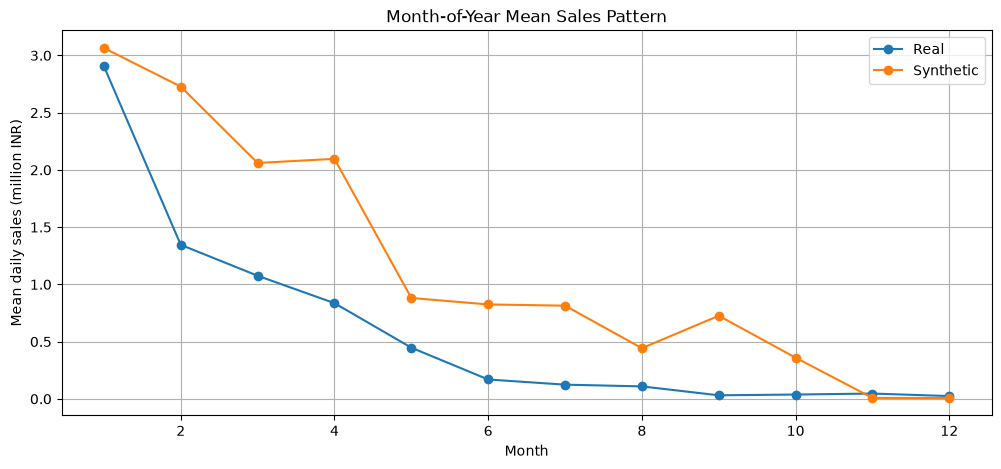

,real,synthetic
quantile,,
0.00,0.000000,0.000000
0.25,0.000000,0.000000
0.50,0.060249,0.000002
0.75,0.551744,0.087167
0.90,1.990909,1.860932
0.95,3.230629,5.629958
0.99,8.667164,21.381505


In [71]:
real_month_profile = (
    real_sales.assign(month=real_sales.index.month)
    .groupby("month")["sales"].mean()
)
synthetic_month_profile = synthetic.groupby(synthetic.index.month)["sales"].mean()

profile_compare = pd.DataFrame({
    "real_mean_sales": real_month_profile,
    "synthetic_mean_sales": synthetic_month_profile,
}) / SALES_SCALE

display(profile_compare)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(profile_compare.index, profile_compare["real_mean_sales"], marker="o", label="Real")
ax.plot(profile_compare.index, profile_compare["synthetic_mean_sales"], marker="o", label="Synthetic")
ax.set_title("Month-of-Year Mean Sales Pattern")
ax.set_xlabel("Month")
ax.set_ylabel("Mean daily sales (million INR)")
ax.legend()
ax.grid(True)
plt.show()

comparison_quantiles = pd.DataFrame({
    "real": real_sales["sales"].quantile([0, .25, .5, .75, .9, .95, .99]),
    "synthetic": synthetic["sales"].quantile([0, .25, .5, .75, .9, .95, .99]),
}) / SALES_SCALE
comparison_quantiles.index.name = "quantile"
display(comparison_quantiles)


## 18. Plot a recent synthetic segment with injected events


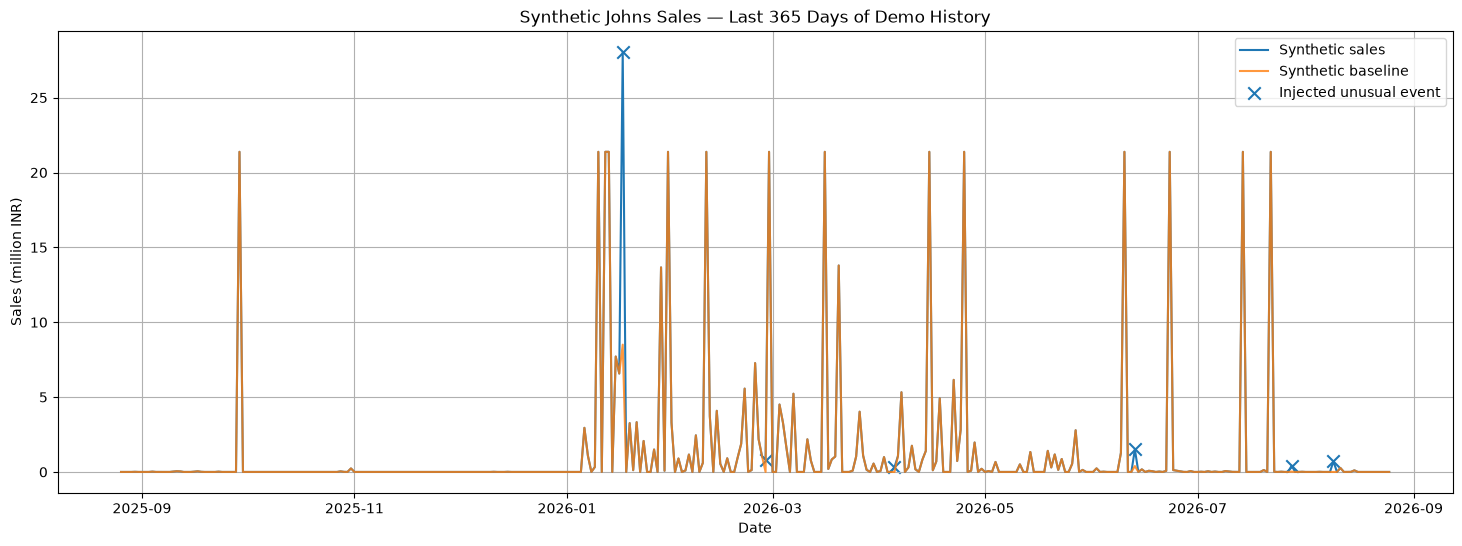

In [49]:
plot_slice = synthetic.iloc[-365:].copy()

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(plot_slice.index, plot_slice["sales"] / SALES_SCALE, label="Synthetic sales")
ax.plot(plot_slice.index, plot_slice["baseline_sales"] / SALES_SCALE, label="Synthetic baseline", alpha=0.8)
events = plot_slice[plot_slice["irregular_event"].eq(1)]
ax.scatter(events.index, events["sales"] / SALES_SCALE, marker="x", s=80, label="Injected unusual event")
ax.set_title("Synthetic Johns Sales — Last 365 Days of Demo History")
ax.set_xlabel("Date")
ax.set_ylabel("Sales (million INR)")
ax.legend()
ax.grid(True)
plt.show()


# Part E — LightGBM feature engineering

For a prediction anchored at day `t`, the model gets:

### Sales history available before the future horizon
- previous-day sales,
- 7-, 14-, and 28-day lags,
- previous 7-, 14-, and 28-day rolling sales summaries.

### Already-observed weather
- recent rainfall totals,
- recent rainy / heavy-rain days,
- recent maximum daily rain,
- precipitation hours.

### Forecast-style weather
- future rainfall total for the model horizon,
- future rainy / heavy / very-wet days,
- future maximum daily rain,
- future precipitation hours.

### Calendar
- month,
- day of week,
- cyclical month and day-of-year terms.

The target is `1` if at least one synthetic unusual-order event happens within the corresponding future horizon.


## 19. Add sales-history and calendar features


In [50]:
def add_sales_and_calendar_features(df):
    x = df.copy()
    sales_m = x["sales"] / SALES_SCALE

    # Use only information strictly before the anchor date for sales features.
    prior_sales = sales_m.shift(1)
    x["sales_lag_1d_m"] = sales_m.shift(1)
    x["sales_lag_7d_m"] = sales_m.shift(7)
    x["sales_lag_14d_m"] = sales_m.shift(14)
    x["sales_lag_28d_m"] = sales_m.shift(28)
    x["sales_mean_prev_7d_m"] = prior_sales.rolling(7, min_periods=7).mean()
    x["sales_mean_prev_14d_m"] = prior_sales.rolling(14, min_periods=14).mean()
    x["sales_mean_prev_28d_m"] = prior_sales.rolling(28, min_periods=28).mean()
    x["sales_sum_prev_7d_m"] = prior_sales.rolling(7, min_periods=7).sum()
    x["sales_sum_prev_28d_m"] = prior_sales.rolling(28, min_periods=28).sum()
    x["zero_sales_days_prev_14d"] = (x["sales"].shift(1) <= 0).astype(int).rolling(14, min_periods=14).sum()

    x["month"] = x.index.month
    x["day_of_week"] = x.index.dayofweek
    x["day_of_year"] = x.index.dayofyear
    x["month_sin"] = np.sin(2 * np.pi * x["month"] / 12.0)
    x["month_cos"] = np.cos(2 * np.pi * x["month"] / 12.0)
    x["doy_sin"] = np.sin(2 * np.pi * x["day_of_year"] / 365.25)
    x["doy_cos"] = np.cos(2 * np.pi * x["day_of_year"] / 365.25)
    x["monsoon_flag"] = x["month"].isin([6, 7, 8, 9]).astype(int)
    x["early_order_season_flag"] = x["month"].isin([1, 2, 3]).astype(int)
    return x

synthetic = add_sales_and_calendar_features(synthetic)


## 20. Define horizon-specific model features


In [51]:
BASE_FEATURES = [
    # Sales history
    "sales_lag_1d_m",
    "sales_lag_7d_m",
    "sales_lag_14d_m",
    "sales_lag_28d_m",
    "sales_mean_prev_7d_m",
    "sales_mean_prev_14d_m",
    "sales_mean_prev_28d_m",
    "sales_sum_prev_7d_m",
    "sales_sum_prev_28d_m",
    "zero_sales_days_prev_14d",

    # Observed weather
    "rain_last_3d",
    "rain_last_7d",
    "rain_last_14d",
    "rainy_days_last_7d",
    "heavy_days_last_14d",
    "max_rain_last_7d",
    "precip_hours_last_7d",

    # Calendar
    "month",
    "day_of_week",
    "month_sin",
    "month_cos",
    "doy_sin",
    "doy_cos",
    "monsoon_flag",
    "early_order_season_flag",
]

def feature_columns_for_horizon(h):
    return BASE_FEATURES + [
        f"forecast_rain_{h}d",
        f"forecast_rainy_days_{h}d",
        f"forecast_heavy_days_{h}d",
        f"forecast_very_wet_days_{h}d",
        f"forecast_max_daily_rain_{h}d",
        f"forecast_precip_hours_{h}d",
    ]

for h in HORIZONS:
    print(h, "days ->", len(feature_columns_for_horizon(h)), "features")


7 days -> 31 features
14 days -> 31 features
21 days -> 31 features


# Part F — Chronological train / validation / test

Do **not** randomly shuffle time-series rows.

The notebook uses:

- first 70% → training,
- next 15% → validation for decision-threshold selection,
- final 15% → untouched test.

The validation threshold maximizes the **F1 score** (harmonic mean of precision and recall). The final test is used only once after the threshold is chosen.


## 21. Dataset and split helpers


In [52]:
def make_model_dataset(df, horizon):
    features = feature_columns_for_horizon(horizon)
    target_col = f"target_irregular_next_{horizon}d"
    data = df[features + [target_col]].dropna().copy()
    data[target_col] = data[target_col].astype(int)
    return data, features, target_col


def chronological_split(data):
    n = len(data)
    train_end = int(n * TRAIN_FRACTION)
    val_end = int(n * (TRAIN_FRACTION + VALIDATION_FRACTION))

    train = data.iloc[:train_end].copy()
    val = data.iloc[train_end:val_end].copy()
    test = data.iloc[val_end:].copy()
    return train, val, test


def choose_f1_threshold(y_true, probabilities):
    thresholds = np.linspace(0.05, 0.95, 181)
    rows = []
    for threshold in thresholds:
        pred = (probabilities >= threshold).astype(int)
        rows.append({
            "threshold": threshold,
            "f1": f1_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
        })
    table = pd.DataFrame(rows).sort_values(
        ["f1", "recall", "precision"], ascending=False
    ).reset_index(drop=True)
    return float(table.iloc[0]["threshold"]), table


def classification_metrics(y_true, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    out = {
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "average_precision": average_precision_score(y_true, probabilities),
    }
    try:
        out["roc_auc"] = roc_auc_score(y_true, probabilities)
    except ValueError:
        out["roc_auc"] = np.nan
    return out, pred


## 22. Train LightGBM models for all horizons


In [53]:
models = {}
model_results = []
threshold_tables = {}
test_predictions = {}
splits = {}

for h in HORIZONS:
    data, features, target_col = make_model_dataset(synthetic, h)
    train, val, test = chronological_split(data)

    print("=" * 80)
    print(f"Horizon: {h} days")
    print("Train:", train.index.min().date(), "->", train.index.max().date(), "rows=", len(train))
    print("Valid:", val.index.min().date(), "->", val.index.max().date(), "rows=", len(val))
    print("Test :", test.index.min().date(), "->", test.index.max().date(), "rows=", len(test))
    print("Train positive rate:", round(train[target_col].mean() * 100, 2), "%")
    print("Test positive rate :", round(test[target_col].mean() * 100, 2), "%")

    model = LGBMClassifier(**MODEL_PARAMS)
    model.fit(train[features], train[target_col])

    val_prob = model.predict_proba(val[features])[:, 1]
    best_threshold, threshold_table = choose_f1_threshold(val[target_col], val_prob)

    test_prob = model.predict_proba(test[features])[:, 1]
    metrics, test_pred = classification_metrics(test[target_col], test_prob, best_threshold)

    # Simple baseline: flag only the top 10% of forecast rainfall observed in training.
    rain_col = f"forecast_rain_{h}d"
    rain_threshold = float(train[rain_col].quantile(0.90))
    baseline_pred = (test[rain_col].values >= rain_threshold).astype(int)
    baseline_metrics = {
        "baseline_precision": precision_score(test[target_col], baseline_pred, zero_division=0),
        "baseline_recall": recall_score(test[target_col], baseline_pred, zero_division=0),
        "baseline_f1": f1_score(test[target_col], baseline_pred, zero_division=0),
    }

    models[h] = model
    threshold_tables[h] = threshold_table
    splits[h] = {"train": train, "validation": val, "test": test, "features": features, "target": target_col}
    test_predictions[h] = pd.DataFrame({
        "actual": test[target_col],
        "probability": test_prob,
        "predicted": test_pred,
        "forecast_rain": test[rain_col],
    }, index=test.index)

    row = {"horizon_days": h, **metrics, **baseline_metrics}
    model_results.append(row)

model_results = pd.DataFrame(model_results).set_index("horizon_days")
display(model_results)


Horizon: 7 days
Train: 2016-09-23 -> 2023-08-28 rows= 2531
Valid: 2023-08-29 -> 2025-02-21 rows= 543
Test : 2025-02-22 -> 2026-08-18 rows= 543
Train positive rate: 7.74 %
Test positive rate : 11.6 %
Horizon: 14 days
Train: 2016-09-23 -> 2023-08-24 rows= 2527
Valid: 2023-08-25 -> 2025-02-15 rows= 541
Test : 2025-02-16 -> 2026-08-11 rows= 542
Train positive rate: 15.51 %
Test positive rate : 22.88 %
Horizon: 21 days
Train: 2016-09-23 -> 2023-08-19 rows= 2522
Valid: 2023-08-20 -> 2025-02-09 rows= 540
Test : 2025-02-10 -> 2026-08-04 rows= 541
Train positive rate: 22.72 %
Test positive rate : 31.79 %


,threshold,precision,recall,f1,balanced_accuracy,average_precision,roc_auc,baseline_precision,baseline_recall,baseline_f1
horizon_days,,,,,,,,,,
7,0.485,0.419355,0.206349,0.276596,0.584425,0.303889,0.717791,0.189655,0.174603,0.181818
14,0.705,0.725000,0.233871,0.353659,0.603778,0.513181,0.706301,0.471429,0.266129,0.340206
21,0.545,0.731343,0.284884,0.410042,0.618052,0.607435,0.716314,0.564103,0.255814,0.352000


## 23. Interpret the evaluation metrics

Because unusual events are intentionally rare, **plain accuracy is not the main metric**.

- **Precision**: among periods the model warns about, how many really contain a synthetic unusual event?
- **Recall**: among all synthetic unusual-event periods, how many did the model catch?
- **F1 score**: balance of precision and recall.
- **Average Precision**: summarizes the precision-recall curve; especially useful for imbalanced classification.
- **Receiver Operating Characteristic Area Under the Curve (ROC AUC)**: ranking quality across thresholds.
- **Balanced accuracy**: averages sensitivity across both classes.

High performance here means the model successfully learned the **simulated rules**. It does not prove those rules are true for Johns.


## 24. Confusion matrices on the untouched test periods


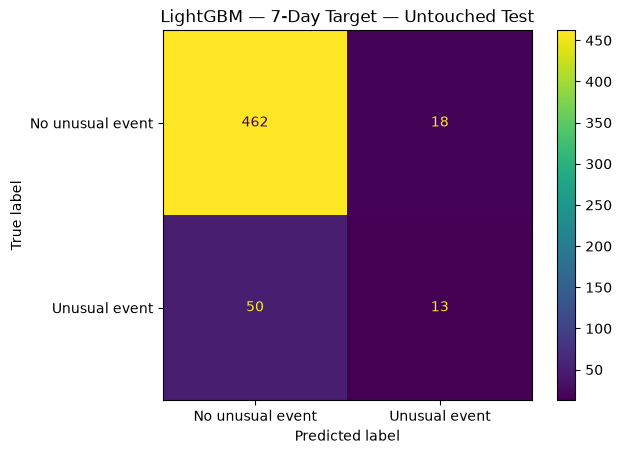

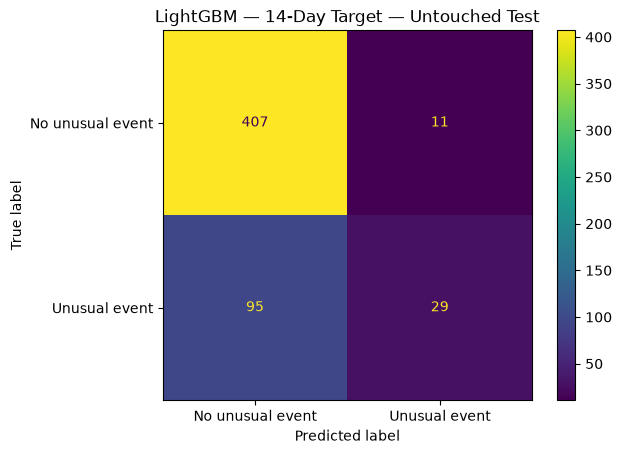

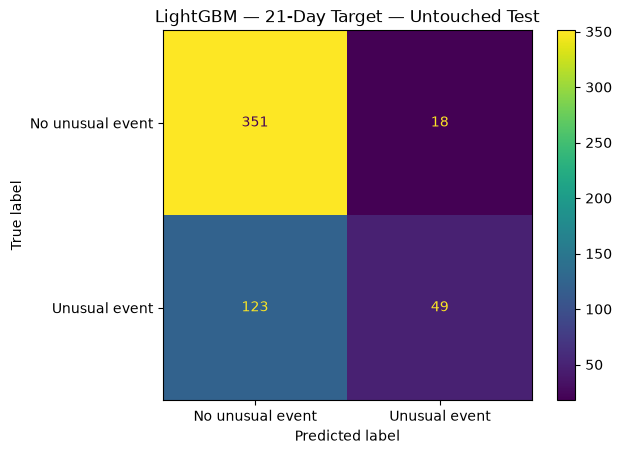

In [54]:
for h in HORIZONS:
    pred_df = test_predictions[h]
    cm = confusion_matrix(pred_df["actual"], pred_df["predicted"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No unusual event", "Unusual event"])
    disp.plot(values_format="d")
    plt.title(f"LightGBM — {h}-Day Target — Untouched Test")
    plt.show()


## 25. Test-period predicted probability over time


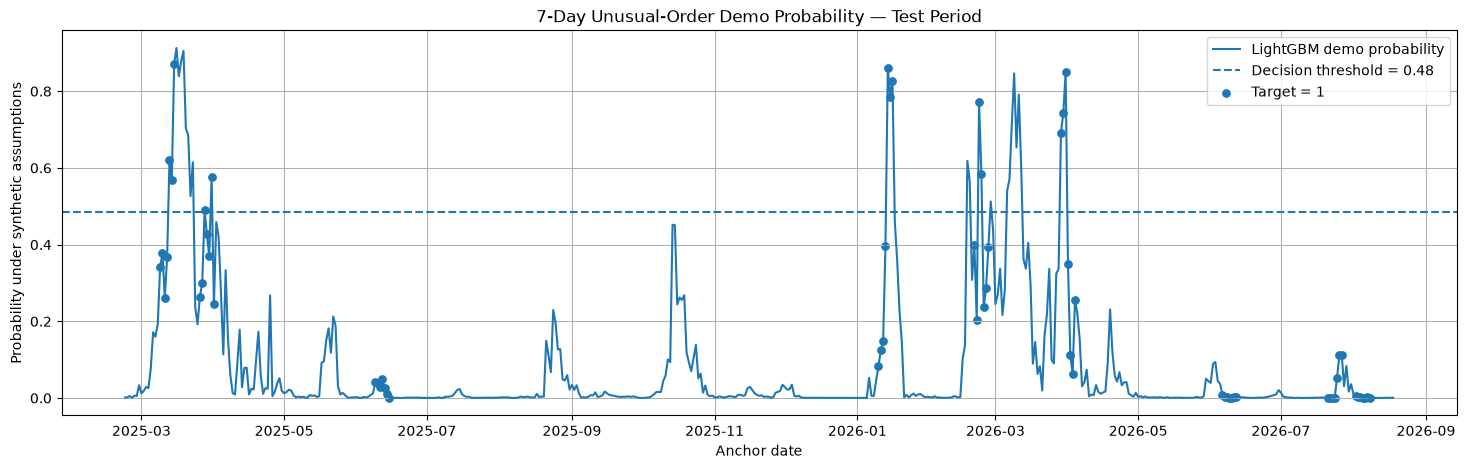

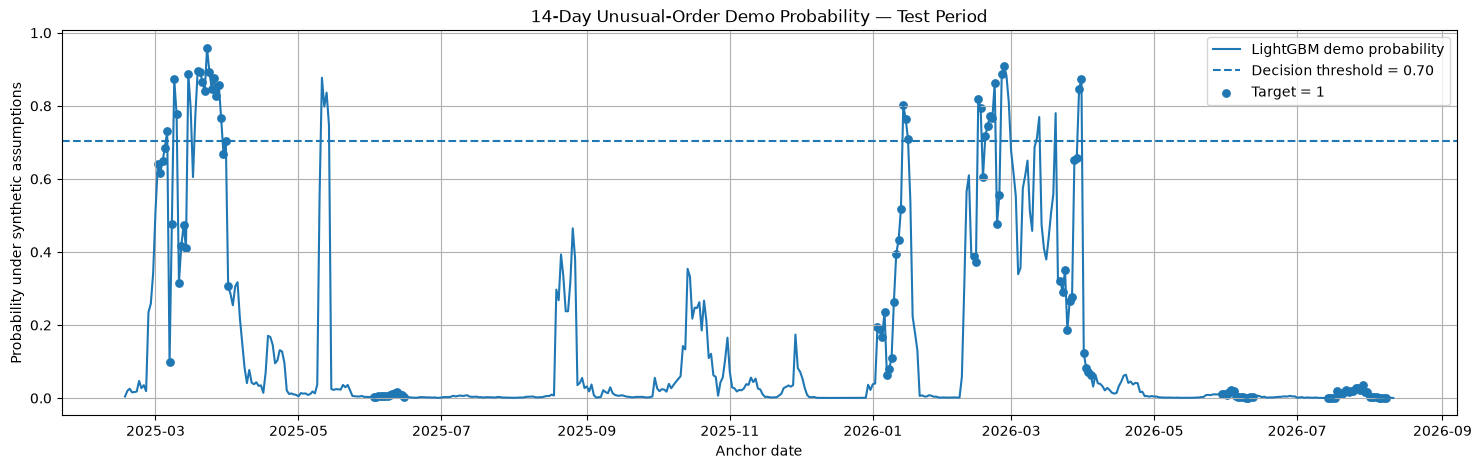

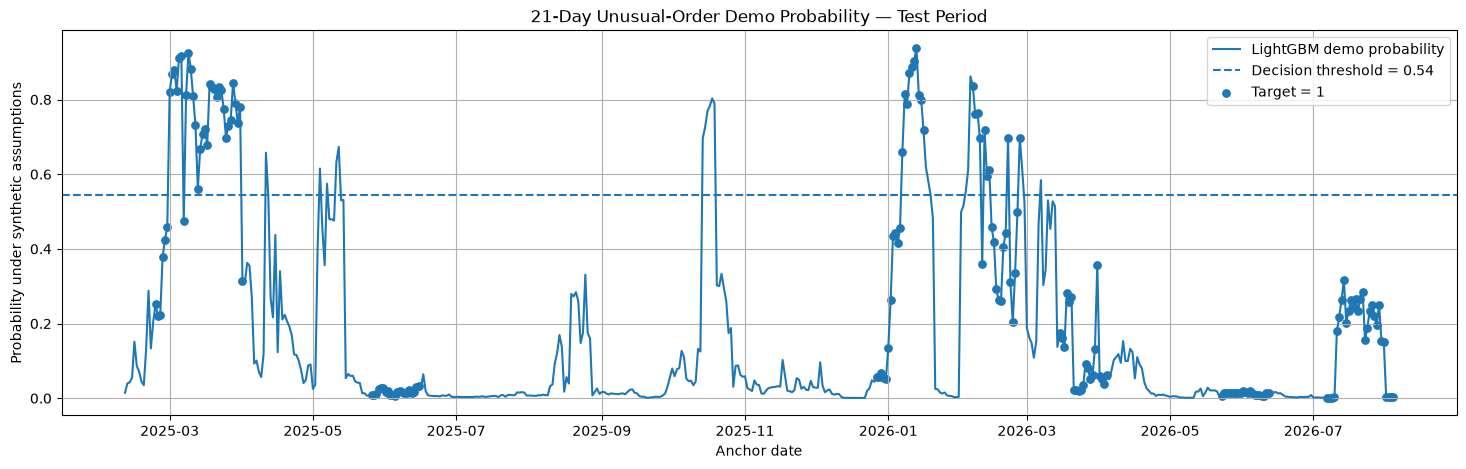

In [55]:
for h in HORIZONS:
    pred_df = test_predictions[h]
    threshold = float(model_results.loc[h, "threshold"])

    fig, ax = plt.subplots(figsize=(18, 5))
    ax.plot(pred_df.index, pred_df["probability"], label="LightGBM demo probability")
    ax.axhline(threshold, linestyle="--", label=f"Decision threshold = {threshold:.2f}")
    actual_event_periods = pred_df[pred_df["actual"].eq(1)]
    ax.scatter(actual_event_periods.index, actual_event_periods["probability"], s=28, label="Target = 1")
    ax.set_title(f"{h}-Day Unusual-Order Demo Probability — Test Period")
    ax.set_ylabel("Probability under synthetic assumptions")
    ax.set_xlabel("Anchor date")
    ax.legend()
    ax.grid(True)
    plt.show()


## 26. Feature importance


,feature,importance_gain,importance_gain_pct
22,doy_cos,9286.849892,18.489553
29,forecast_max_daily_rain_7d,6755.815470,13.450418
5,sales_mean_prev_14d_m,3515.938589,7.000020
15,max_rain_last_7d,3198.253965,6.367529
21,doy_sin,2709.049484,5.393553
6,sales_mean_prev_28d_m,2568.916190,5.114556
10,rain_last_3d,2428.904232,4.835801
9,zero_sales_days_prev_14d,2359.554438,4.697729
30,forecast_precip_hours_7d,2270.597139,4.520621
25,forecast_rain_7d,2258.312633,4.496163


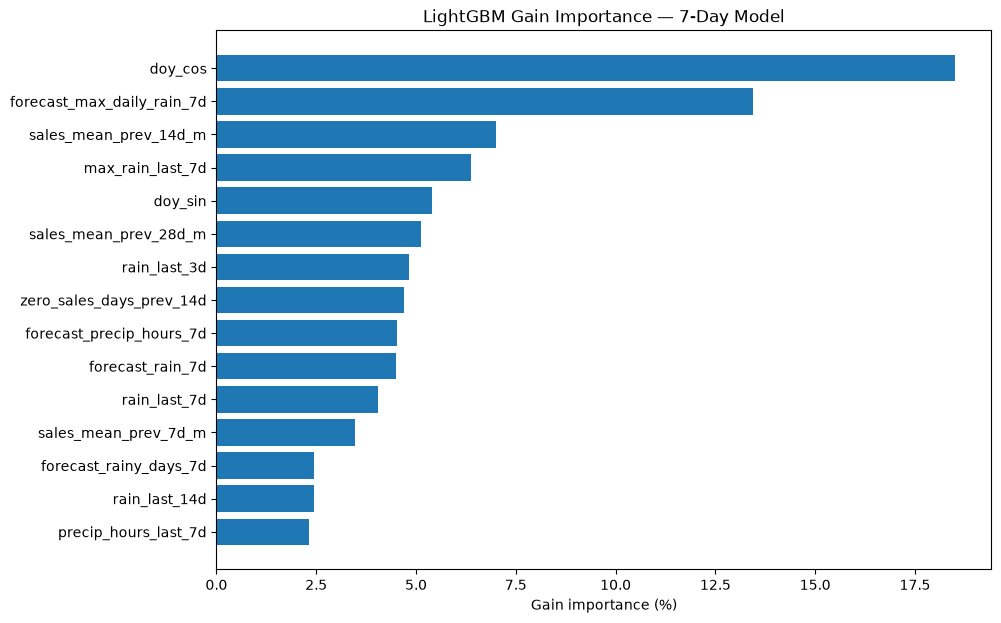

,feature,importance_gain,importance_gain_pct
22,doy_cos,9951.646352,20.647083
29,forecast_max_daily_rain_14d,6534.673251,13.557751
25,forecast_rain_14d,4559.971978,9.460758
21,doy_sin,3450.159406,7.158185
4,sales_mean_prev_7d_m,2699.061678,5.599852
15,max_rain_last_7d,2515.697434,5.219419
6,sales_mean_prev_28d_m,2364.881743,4.906516
9,zero_sales_days_prev_14d,2048.562867,4.250236
27,forecast_heavy_days_14d,1848.947560,3.836086
30,forecast_precip_hours_14d,1379.014265,2.861097


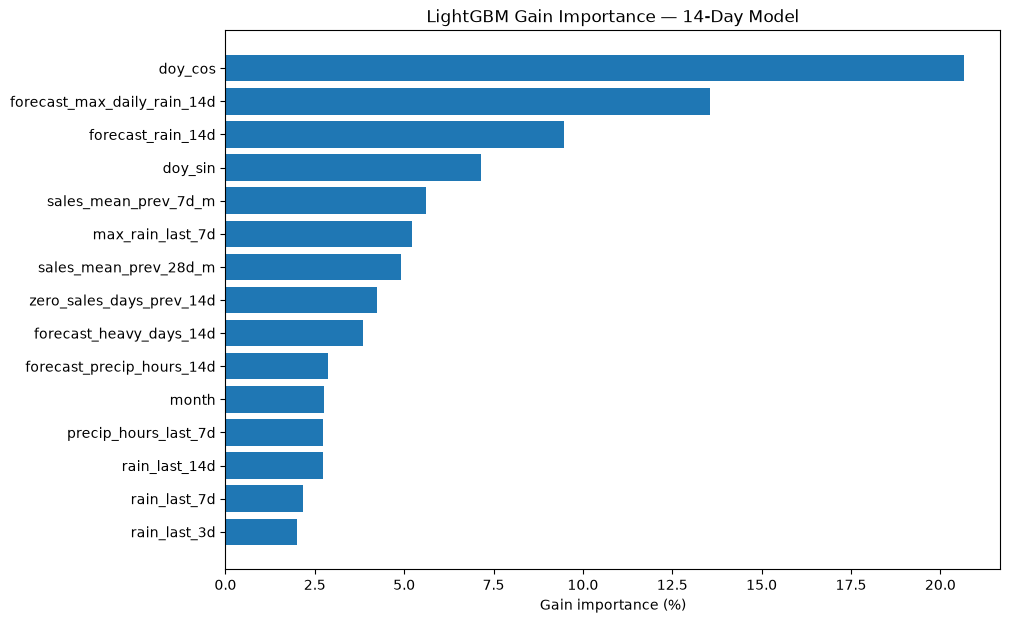

,feature,importance_gain,importance_gain_pct
29,forecast_max_daily_rain_21d,9812.431303,20.688525
22,doy_cos,8691.024891,18.324153
25,forecast_rain_21d,4286.148886,9.036914
6,sales_mean_prev_28d_m,4106.461374,8.658061
21,doy_sin,3300.825970,6.959460
15,max_rain_last_7d,2179.417553,4.595083
17,month,1691.927616,3.567259
30,forecast_precip_hours_21d,1486.786062,3.134739
27,forecast_heavy_days_21d,1430.606705,3.016290
5,sales_mean_prev_14d_m,1299.018217,2.738849


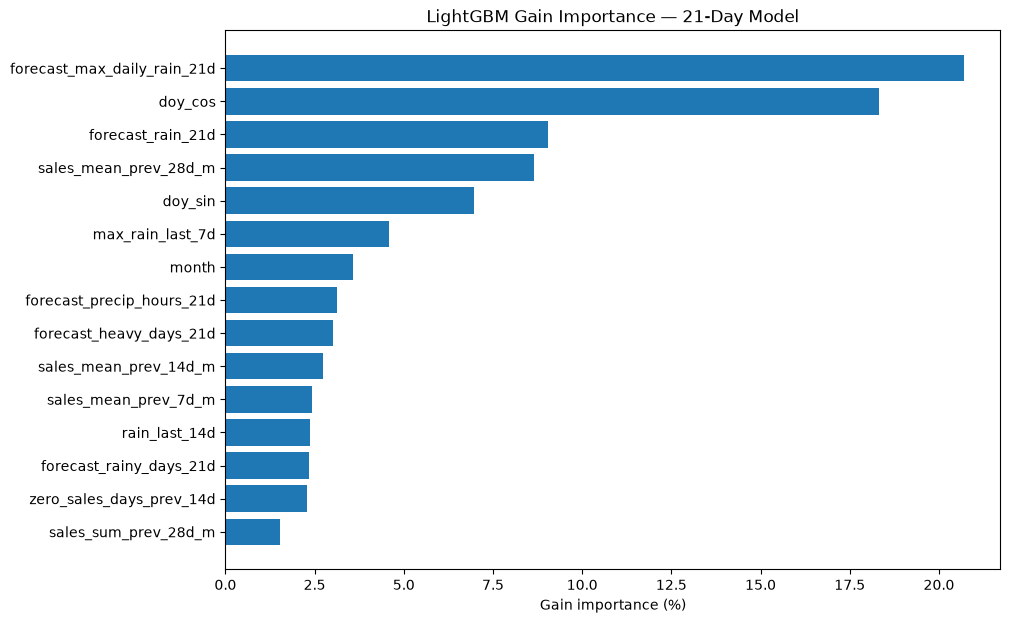

In [56]:
feature_importance_tables = {}

for h in HORIZONS:
    model = models[h]
    features = splits[h]["features"]
    imp = pd.DataFrame({
        "feature": features,
        "importance_gain": model.booster_.feature_importance(importance_type="gain"),
    }).sort_values("importance_gain", ascending=False)
    imp["importance_gain_pct"] = 100 * imp["importance_gain"] / max(imp["importance_gain"].sum(), 1e-12)
    feature_importance_tables[h] = imp

    display(imp.head(15))

    top = imp.head(15).sort_values("importance_gain")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top["feature"], top["importance_gain_pct"])
    ax.set_title(f"LightGBM Gain Importance — {h}-Day Model")
    ax.set_xlabel("Gain importance (%)")
    plt.show()


## 27. Sanity check: does predicted risk rise with synthetic weather pressure?

This is not a causal test. It is only a diagnostic that the trained model responds in the direction expected from the simulation design.


In [57]:
for h in HORIZONS:
    pred_df = test_predictions[h].copy()
    test_index = pred_df.index
    pred_df["weather_pressure"] = synthetic.loc[test_index, "weather_pressure"]
    pred_df["pressure_bin"] = pd.qcut(pred_df["weather_pressure"], q=5, duplicates="drop")
    pressure_summary = pred_df.groupby("pressure_bin", observed=True).agg(
        mean_probability=("probability", "mean"),
        actual_positive_rate=("actual", "mean"),
        rows=("actual", "size"),
    )
    print(f"\n{h}-day model")
    display(pressure_summary)



7-day model


,mean_probability,actual_positive_rate,rows
pressure_bin,,,
"(0.015299999999999998, 0.253]",0.008784,0.018349,109
"(0.253, 0.434]",0.023755,0.083333,108
"(0.434, 0.589]",0.053483,0.027523,109
"(0.589, 0.733]",0.166429,0.111111,108
"(0.733, 0.973]",0.190085,0.339450,109



14-day model


,mean_probability,actual_positive_rate,rows
pressure_bin,,,
"(0.015299999999999998, 0.254]",0.037026,0.110092,109
"(0.254, 0.441]",0.065638,0.148148,108
"(0.441, 0.588]",0.101397,0.037037,108
"(0.588, 0.733]",0.227889,0.222222,108
"(0.733, 0.973]",0.270707,0.623853,109



21-day model


,mean_probability,actual_positive_rate,rows
pressure_bin,,,
"(0.015299999999999998, 0.253]",0.150298,0.266055,109
"(0.253, 0.436]",0.089898,0.222222,108
"(0.436, 0.586]",0.131219,0.148148,108
"(0.586, 0.733]",0.250040,0.277778,108
"(0.733, 0.973]",0.262466,0.675926,108


# Part G — Optional real-data diagnostic only

We still **do not have confirmed real labels** saying which Johns sales spikes were weather-driven emergency replenishments. Therefore we should not pretend to evaluate the classifier on real targets.

This section merely overlays the real aggregate sales series with rainfall so you can visually inspect candidate periods for later business validation.


## 28. Join available real sales with historical weather


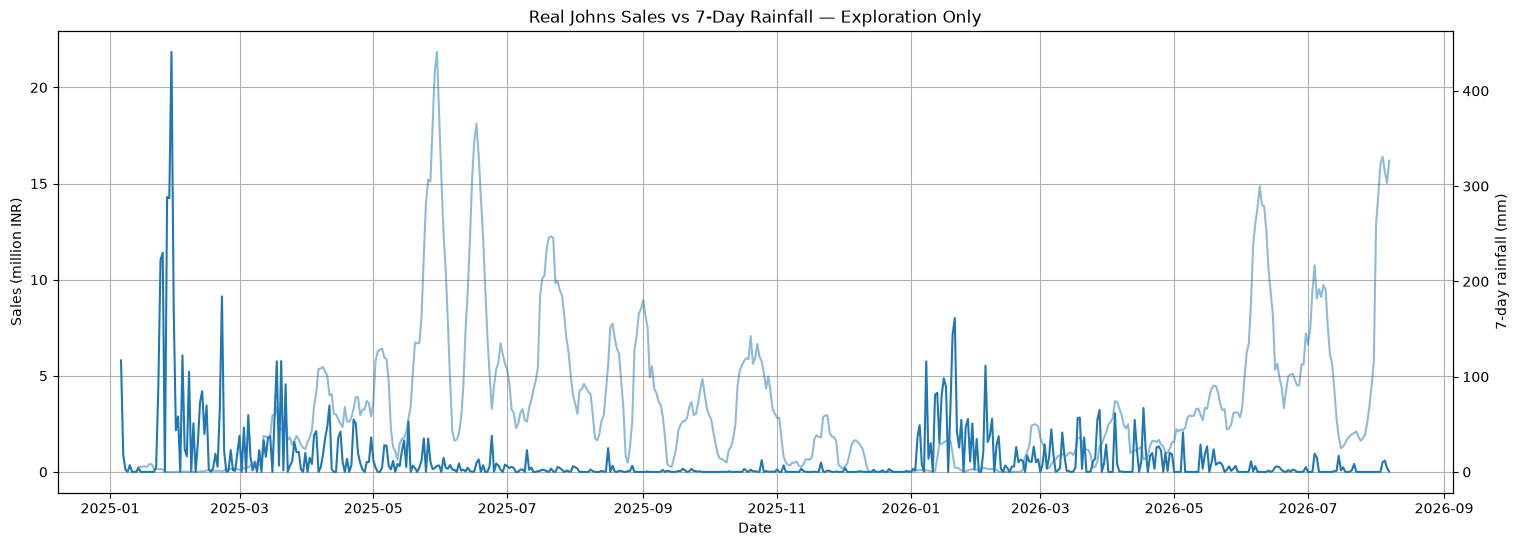

In [58]:
real_compare = real_sales.join(historical_weather[["rain_sum", "precipitation_hours"]], how="left")
real_compare["rain_7d"] = real_compare["rain_sum"].rolling(7, min_periods=7).sum()
real_compare["sales_rolling_median_28d"] = real_compare["sales"].rolling(28, min_periods=14).median()
real_compare["sales_ratio_to_28d_median"] = (
    real_compare["sales"] / real_compare["sales_rolling_median_28d"].replace(0, np.nan)
)

fig, ax1 = plt.subplots(figsize=(18, 6))
ax1.plot(real_compare.index, real_compare["sales"] / SALES_SCALE, label="Real sales")
ax1.set_ylabel("Sales (million INR)")
ax1.set_xlabel("Date")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(real_compare.index, real_compare["rain_7d"], alpha=0.5, label="7-day rainfall")
ax2.set_ylabel("7-day rainfall (mm)")

ax1.set_title("Real Johns Sales vs 7-Day Rainfall — Exploration Only")
plt.show()


# Part H — Live forecast scoring

The live output is meaningful only as a **demo under the synthetic rules**.

The LightGBM models require:

1. recent Johns sales-history features,
2. recent observed-weather features,
3. future weather forecast features.

The Open-Meteo Forecast API is used here with past days as well as future days so the recent observed-weather features are available from one operational call.

### Important

If the latest sales date is too old, the notebook refuses live scoring by default. Update the Odoo export first. This avoids silently pretending that missing recent sales are zero.


## 29. Download recent + future Open-Meteo weather


In [59]:
def fetch_live_weather(latitude, longitude, timezone, past_days=35, forecast_days=16):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "past_days": past_days,
        "forecast_days": forecast_days,
        "precipitation_unit": "mm",
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if "daily" not in payload:
        raise ValueError(f"Unexpected live weather response: {payload}")

    df = pd.DataFrame(payload["daily"])
    df["date"] = pd.to_datetime(df["time"])
    df = df.drop(columns=["time"]).set_index("date").sort_index()
    for col in ["rain_sum", "precipitation_sum", "precipitation_hours"]:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)
    return df

live_weather = fetch_live_weather(
    location["latitude"],
    location["longitude"],
    location["timezone"],
    past_days=35,
    forecast_days=16,
)

display(live_weather.tail(20))


,rain_sum,precipitation_sum,precipitation_hours
date,,,
2026-08-28,1.30,3.30,14.0
2026-08-29,4.10,7.00,19.0
2026-08-30,0.20,0.40,3.0
2026-08-31,0.80,1.80,9.0
2026-09-01,0.00,0.00,0.0
2026-09-02,0.40,0.70,3.0
2026-09-03,0.30,0.70,3.0
2026-09-04,0.10,0.10,1.0
2026-09-05,0.30,0.30,3.0


## 30. Build a single operational feature row


In [60]:
def risk_band(probability):
    # Management-friendly demo bands only; not calibrated real-world risk categories.
    if probability < 0.25:
        return "LOW"
    if probability < 0.50:
        return "MEDIUM"
    if probability < 0.75:
        return "HIGH"
    return "EXTREME"


def build_live_feature_row(real_sales_df, observed_weather_df, future_weather_df, anchor_date, horizon):
    anchor_date = pd.Timestamp(anchor_date).normalize()
    feature_names = feature_columns_for_horizon(horizon)
    row = {}

    # --------------------
    # Sales history
    # --------------------
    sales_m = (real_sales_df["sales"] / SALES_SCALE).sort_index()
    prior = sales_m.loc[:anchor_date].shift(1)

    def at_anchor(series):
        value = series.reindex([anchor_date]).iloc[0]
        return float(value) if pd.notna(value) else np.nan

    row["sales_lag_1d_m"] = at_anchor(sales_m.shift(1))
    row["sales_lag_7d_m"] = at_anchor(sales_m.shift(7))
    row["sales_lag_14d_m"] = at_anchor(sales_m.shift(14))
    row["sales_lag_28d_m"] = at_anchor(sales_m.shift(28))
    row["sales_mean_prev_7d_m"] = at_anchor(prior.rolling(7, min_periods=7).mean())
    row["sales_mean_prev_14d_m"] = at_anchor(prior.rolling(14, min_periods=14).mean())
    row["sales_mean_prev_28d_m"] = at_anchor(prior.rolling(28, min_periods=28).mean())
    row["sales_sum_prev_7d_m"] = at_anchor(prior.rolling(7, min_periods=7).sum())
    row["sales_sum_prev_28d_m"] = at_anchor(prior.rolling(28, min_periods=28).sum())
    row["zero_sales_days_prev_14d"] = at_anchor(
        (real_sales_df["sales"].shift(1) <= 0).astype(int).rolling(14, min_periods=14).sum()
    )

    # --------------------
    # Observed weather through anchor date
    # --------------------
    ow = observed_weather_df.sort_index().loc[:anchor_date].copy()
    if len(ow) < 14:
        raise ValueError("Need at least 14 days of observed weather through the anchor date.")

    recent3 = ow.tail(3)
    recent7 = ow.tail(7)
    recent14 = ow.tail(14)

    row["rain_last_3d"] = float(recent3["rain_sum"].sum())
    row["rain_last_7d"] = float(recent7["rain_sum"].sum())
    row["rain_last_14d"] = float(recent14["rain_sum"].sum())
    row["rainy_days_last_7d"] = int((recent7["rain_sum"] >= RAINY_DAY_MM).sum())
    row["heavy_days_last_14d"] = int((recent14["rain_sum"] >= HEAVY_RAIN_DAY_MM).sum())
    row["max_rain_last_7d"] = float(recent7["rain_sum"].max())
    row["precip_hours_last_7d"] = float(recent7["precipitation_hours"].sum())

    # --------------------
    # Calendar
    # --------------------
    month = anchor_date.month
    dow = anchor_date.dayofweek
    doy = anchor_date.dayofyear
    row["month"] = month
    row["day_of_week"] = dow
    row["month_sin"] = math.sin(2 * math.pi * month / 12.0)
    row["month_cos"] = math.cos(2 * math.pi * month / 12.0)
    row["doy_sin"] = math.sin(2 * math.pi * doy / 365.25)
    row["doy_cos"] = math.cos(2 * math.pi * doy / 365.25)
    row["monsoon_flag"] = int(month in [6, 7, 8, 9])
    row["early_order_season_flag"] = int(month in [1, 2, 3])

    # --------------------
    # Future forecast after anchor date
    # --------------------
    fw = future_weather_df.sort_index()
    fw = fw[fw.index > anchor_date].head(horizon)
    if len(fw) < horizon:
        return None, len(fw)

    row[f"forecast_rain_{horizon}d"] = float(fw["rain_sum"].sum())
    row[f"forecast_rainy_days_{horizon}d"] = int((fw["rain_sum"] >= RAINY_DAY_MM).sum())
    row[f"forecast_heavy_days_{horizon}d"] = int((fw["rain_sum"] >= HEAVY_RAIN_DAY_MM).sum())
    row[f"forecast_very_wet_days_{horizon}d"] = int((fw["rain_sum"] >= VERY_WET_DAY_MM).sum())
    row[f"forecast_max_daily_rain_{horizon}d"] = float(fw["rain_sum"].max())
    row[f"forecast_precip_hours_{horizon}d"] = float(fw["precipitation_hours"].sum())

    frame = pd.DataFrame([row], index=[anchor_date])
    return frame[feature_names], len(fw)


## 31. Run live demo scoring where enough forecast days are available


In [61]:
today = pd.Timestamp.today().normalize()
anchor_date = real_sales.index.max().normalize()
staleness_days = int((today - anchor_date).days)

print("Today:", today.date())
print("Latest Johns sales date:", anchor_date.date())
print("Sales staleness (days):", staleness_days)

# Combine archive and live recent weather. Live rows win on duplicate dates.
observed_weather = pd.concat([historical_weather, live_weather]).sort_index()
observed_weather = observed_weather[~observed_weather.index.duplicated(keep="last")]

if staleness_days > MAX_LIVE_SALES_STALENESS_DAYS:
    print(
        "\nLIVE SCORING SKIPPED: the Johns sales export is too stale.\n"
        f"Update johns_daily_sales.csv so its final date is within {MAX_LIVE_SALES_STALENESS_DAYS} days of today."
    )
    live_risk_table = pd.DataFrame()
else:
    live_rows = []
    for h in HORIZONS:
        feature_row, available_days = build_live_feature_row(
            real_sales,
            observed_weather,
            live_weather,
            anchor_date,
            h,
        )

        if feature_row is None:
            live_rows.append({
                "horizon_days": h,
                "status": f"SKIPPED — only {available_days} future days available",
            })
            continue

        probability = float(models[h].predict_proba(feature_row)[:, 1][0])
        threshold = float(model_results.loc[h, "threshold"])
        live_rows.append({
            "horizon_days": h,
            "anchor_date": anchor_date.date(),
            "demo_model_probability": probability,
            "decision_threshold": threshold,
            "warning": int(probability >= threshold),
            "risk_band": risk_band(probability),
            "forecast_rain_mm": float(feature_row.iloc[0][f"forecast_rain_{h}d"]),
            "forecast_rainy_days": int(feature_row.iloc[0][f"forecast_rainy_days_{h}d"]),
            "forecast_heavy_days": int(feature_row.iloc[0][f"forecast_heavy_days_{h}d"]),
            "status": "OK",
        })

    live_risk_table = pd.DataFrame(live_rows)
    display(live_risk_table)


Today: 2026-09-01
Latest Johns sales date: 2026-08-07
Sales staleness (days): 25

LIVE SCORING SKIPPED: the Johns sales export is too stale.
Update johns_daily_sales.csv so its final date is within 2 days of today.


### Why the 21-day live row may be skipped

The model can be trained for a 21-day target because the synthetic historical weather contains long future windows. The operational weather endpoint may return fewer than 21 future daily rows in the configuration above. The notebook therefore **skips** a horizon rather than inventing missing forecast weather.

For a real 21-day operational model, supply a weather source that genuinely provides the required 21-day forecast horizon, or use an explicitly labelled scenario forecast.


# Part I — What-if scenario scoring

This helper lets you test a user-supplied weather scenario. It is useful when you want to demonstrate a 21-day case even if the live weather endpoint does not contain enough future days.

The scenario must contain daily columns:

- `rain_sum`
- `precipitation_sum`
- `precipitation_hours`

and a daily DatetimeIndex strictly after the anchor date.


## 32. Scenario scorer


In [62]:
def score_weather_scenario(scenario_weather, horizon, anchor_date=None):
    if horizon not in models:
        raise ValueError(f"No trained model for {horizon} days")

    if anchor_date is None:
        anchor_date = real_sales.index.max().normalize()
    else:
        anchor_date = pd.Timestamp(anchor_date).normalize()

    required_cols = {"rain_sum", "precipitation_sum", "precipitation_hours"}
    missing = required_cols - set(scenario_weather.columns)
    if missing:
        raise KeyError(f"Scenario is missing columns: {missing}")

    observed = pd.concat([historical_weather, live_weather]).sort_index()
    observed = observed[~observed.index.duplicated(keep="last")]

    row, available = build_live_feature_row(
        real_sales,
        observed,
        scenario_weather,
        anchor_date,
        horizon,
    )
    if row is None:
        raise ValueError(f"Scenario has only {available} future days; need {horizon}.")

    probability = float(models[horizon].predict_proba(row)[:, 1][0])
    threshold = float(model_results.loc[horizon, "threshold"])

    return pd.DataFrame([{
        "horizon_days": horizon,
        "demo_model_probability": probability,
        "decision_threshold": threshold,
        "warning": int(probability >= threshold),
        "risk_band": risk_band(probability),
        "scenario_rain_mm": float(row.iloc[0][f"forecast_rain_{horizon}d"]),
        "scenario_rainy_days": int(row.iloc[0][f"forecast_rainy_days_{horizon}d"]),
        "scenario_heavy_days": int(row.iloc[0][f"forecast_heavy_days_{horizon}d"]),
    }])


## 33. Example 21-day heavy-rain what-if scenario


In [63]:
scenario_anchor = real_sales.index.max().normalize()
scenario_dates = pd.date_range(scenario_anchor + pd.Timedelta(days=1), periods=21, freq="D")

# Intentionally artificial weather scenario for demonstration only.
scenario_rng = np.random.default_rng(123)
scenario_rain = np.where(
    scenario_rng.random(21) < 0.80,
    scenario_rng.gamma(shape=2.2, scale=16.0, size=21),
    0.0,
)

heavy_21d_scenario = pd.DataFrame({
    "rain_sum": scenario_rain,
    "precipitation_sum": scenario_rain,
    "precipitation_hours": np.where(scenario_rain > 0, np.minimum(24, 2 + scenario_rain / 7), 0),
}, index=scenario_dates)

if (pd.Timestamp.today().normalize() - scenario_anchor).days <= MAX_LIVE_SALES_STALENESS_DAYS:
    display(score_weather_scenario(heavy_21d_scenario, 21, scenario_anchor))
else:
    print("Scenario scoring skipped because the real sales export is stale. Update the CSV first.")


Scenario scoring skipped because the real sales export is stale. Update the CSV first.


# Part J — Export artifacts

The exported synthetic dataset should always be labelled as synthetic if it is shared.


## 34. Save datasets, metrics, models, and predictions


In [64]:
# Keep only useful columns in the synthetic export.
synthetic.to_csv(EXPORT_DIR / "johns_semisynthetic_lightgbm_demo_history.csv", index=True)
model_results.to_csv(EXPORT_DIR / "johns_lightgbm_demo_metrics.csv", index=True)

for h in HORIZONS:
    test_predictions[h].to_csv(EXPORT_DIR / f"johns_lightgbm_{h}d_test_predictions.csv", index=True)
    feature_importance_tables[h].to_csv(EXPORT_DIR / f"johns_lightgbm_{h}d_feature_importance.csv", index=False)
    threshold_tables[h].to_csv(EXPORT_DIR / f"johns_lightgbm_{h}d_threshold_search.csv", index=False)
    joblib.dump(models[h], EXPORT_DIR / f"johns_lightgbm_{h}d_demo_model.joblib")

if isinstance(live_risk_table, pd.DataFrame) and not live_risk_table.empty:
    live_risk_table.to_csv(EXPORT_DIR / "johns_lightgbm_live_demo_risk.csv", index=False)

metadata = {
    "warning": "SYNTHETIC DEMO MODEL — NOT A VALIDATED REAL-WORLD JOHNS ORDER PROBABILITY",
    "real_sales_start": str(real_sales.index.min().date()),
    "real_sales_end": str(real_sales.index.max().date()),
    "synthetic_start": str(synthetic.index.min().date()),
    "synthetic_end": str(synthetic.index.max().date()),
    "location": location,
    "horizons_days": HORIZONS,
    "random_state": RANDOM_STATE,
    "simulation": {
        "base_trigger_probability": BASE_TRIGGER_PROBABILITY,
        "trigger_pressure_start": TRIGGER_PRESSURE_START,
        "max_trigger_probability": MAX_TRIGGER_PROBABILITY,
        "event_cooldown_days": EVENT_COOLDOWN_DAYS,
        "event_delay_days": [MIN_EVENT_DELAY_DAYS, MAX_EVENT_DELAY_DAYS],
    },
}

with open(EXPORT_DIR / "README_SYNTHETIC_DEMO_METADATA.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved outputs to:", EXPORT_DIR.resolve())


Saved outputs to: C:\Users\adithyankg\OneDrive\Pictures\statistical_models\johns\09_lightGBM\johns_lightgbm_demo_outputs


# Final interpretation guide

## What the model is actually predicting

For each horizon, LightGBM answers:

> **Under the synthetic rules used in this notebook, how likely is at least one unusual aggregate Johns order event within the next N days, given recent sales, recent weather, the calendar, and forecast weather?**

It does **not** answer:

> “There is a scientifically validated 78% real-world chance Johns will get an emergency order.”

## Why aggregate daily sales are sufficient for this demo

The business target is not *which retailer* will order. It is whether **unusual aggregate order activity from any retailer(s)** may occur. Therefore the training target is aggregate and retailer identifiers are not required.

## Why synthetic data is useful here

It lets us test:

- whether the complete data pipeline works,
- how to create horizon-specific targets,
- how LightGBM combines nonlinear weather and sales features,
- how to evaluate an imbalanced classification problem,
- how a management warning could be generated from a future weather forecast.

## What synthetic data cannot prove

Synthetic data cannot establish that heavy rain truly causes Johns retailers to reorder. The generator contains that relationship because **we coded it into the simulation**.

## Production upgrade path

When more real Johns history is available:

1. Define a real unusual-order target with business stakeholders.
2. Label historical events, ideally distinguishing planned early-season bulk orders from emergency / unplanned replenishment.
3. Keep aggregate modelling if the business only needs an overall warning.
4. Add retailer-level data later only if the business needs *which retailer* is likely to reorder.
5. Replace perfect historical future weather with weather forecasts that were actually available at each historical prediction date.
6. Use rolling / walk-forward validation across multiple years and monsoons.
7. Calibrate predicted probabilities before presenting them as operational probabilities.
8. Compare LightGBM against simple rules, logistic regression, survival models, and the existing Isolation Forest weather-anomaly signal.


# Suggested experiment checklist

- [ ] Run the Odoo PostgreSQL export and save `johns_daily_sales.csv`.
- [ ] Run the notebook once without changing the simulation rules.
- [ ] Inspect real vs synthetic month-of-year patterns.
- [ ] Check how many synthetic unusual events were generated.
- [ ] Inspect class rates for 7-, 14-, and 21-day targets.
- [ ] Compare LightGBM F1 score and recall with the simple high-rainfall baseline.
- [ ] Inspect feature importance; forecast-weather features should matter in the synthetic experiment.
- [ ] Change the synthetic trigger assumptions and rerun to see how sensitive the model is.
- [ ] Update the Odoo sales export before live scoring.
- [ ] Never present the synthetic probability as a validated Johns business probability.


# Official references

- LightGBM Python / scikit-learn API: https://lightgbm.readthedocs.io/en/stable/Python-API.html
- LightGBM `LGBMClassifier`: https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMClassifier.html
- Open-Meteo Forecast API: https://open-meteo.com/en/docs
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api
- Open-Meteo Historical Forecast API: https://open-meteo.com/en/docs/historical-forecast-api
